In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from mytools.plot import (
    plot_heatmaps,
    plot_profile_2c,
    save_plot,
    make_figure
)
from mytools.estimate import get_signal_level
from mytools.data import read_h5, vitems

In [3]:
data_path = "../data/halo_subtracted_result_nulltest_random_halofitting_nfw_gaussian_const_sectormask_maskpeak.h5"
vitems(data_path)

Item: random_crafts_df122k_rmfg15_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: random_crafts_df122k_rmfg15_xsize3000_nfs10/fit_cov
Type: Dataset
Shape: (7, 7)
Dtype: float64
Attributes (0):
 None
Item: random_crafts_df122k_rmfg15_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: random_crafts_df122k_rmfg15_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: random_crafts_df122k_rmfg15_xsize3000_nfs10/res
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: random_crafts_df122k_rmfg15_xsize3000_nfs10/stack
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: random_crafts_df122k_rmfg30_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: random_crafts_df122k_rmfg30_xsize3000_nfs10/fit_cov
Type: Dataset
Shape: (7, 7)
Dtype: float64
Attributes (0):
 None
Item: random_crafts_df122k_rmfg30_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 1

In [4]:
modes = [15, 30]
keys = [
    f"random_crafts_df122k_rmfg{mode}_xsize3000_nfs10/{k}"
    for k in ["stack"] for mode in modes
]

stack_15, stack_30 = read_h5(data_path, keys)

Plot saved to img_random_crafts_df122k_rmfg_compare_xsize3000_nfs10_mean.png


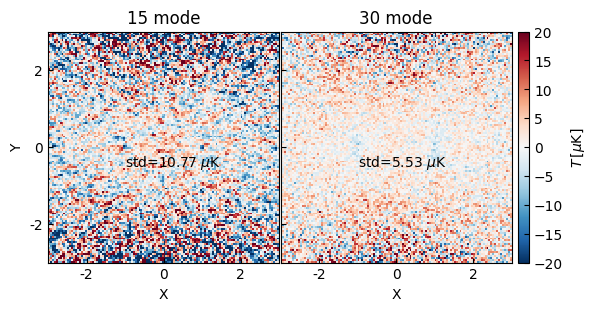

In [5]:
fig, axes = make_figure(1,2, figsize=(6, 3), wspace=0.)
plot_heatmaps(
    [stack_15, stack_30], 
    title=['15 mode', '30 mode'],
    show_cbar=[False, True], 
    vmax=20, vmin=-20, 
    axes=axes, 
    cmap='RdBu_r'
)
axes[0].text(40, 50, r'std=%.2f $\mu$K'%stack_15.std())
axes[1].text(40, 50, r'std=%.2f $\mu$K'%stack_30.std())

fname = 'img_random_crafts_df122k_rmfg_compare_xsize3000_nfs10_mean.png'
save_plot(fig, fname, dpi=300)

In [6]:
def plot_mask_signal(data, weight, bounds=None, axes=None):
    mean, std = data.mean(), data.std()
    print(mean, std)

    lx, ly, _, params, _ = get_signal_level(
    data, weight, bounds=bounds, show_fit=False, print_info=False
    )

    _axes = plot_profile_2c(lx, ly, width=params[2], axes=axes)
    _axes[0].fill_betweenx([-10, 10], -3, -1, color="k", alpha=0.3)
    _axes[0].fill_betweenx([-10, 10], 1, 3, color="k", alpha=0.3)
    _axes[1].fill_between(lx[-1], mean+std, mean - std, color='pink', alpha=0.5)

    return _axes

In [7]:
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0., 0.6),  # sigma
}

weight = None
weight = np.ones_like(stack_15)
weight[:40] = 0
weight[80:] = 0

-0.7821430193100529 10.76504941057189
width: 0.2356423320287412
width_pix: 5
1.2833066342776658 5.526993739510874
width: 0.5999999999999014
width_pix: 12


(-7.0, 20.0)

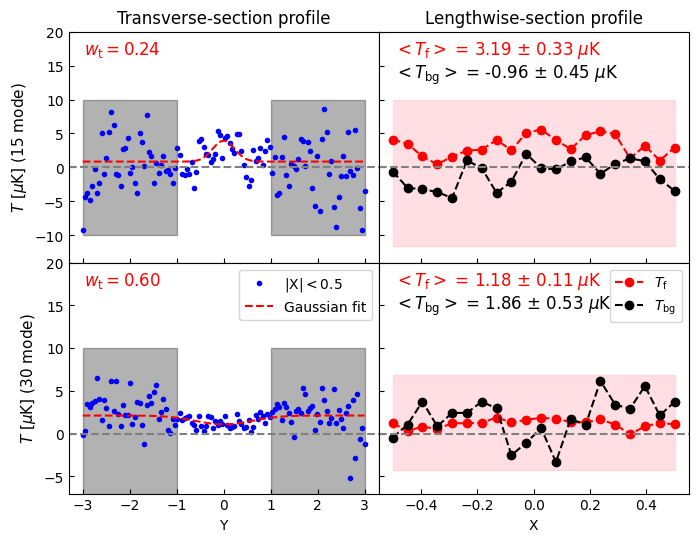

In [8]:
fig, axes = make_figure(2,2, sharex='col', sharey='row', aspect=None, figsize=(8,6))
_ = plot_mask_signal(stack_15, weight, bounds, axes=axes[0])
_ = plot_mask_signal(stack_30, weight, bounds, axes=axes[1])

axes[1,0].set_title('')
axes[1,1].set_title('')
axes[0,0].get_legend().remove()
axes[0,1].get_legend().remove()
axes[0,0].set_ylim(-14, 20)
axes[1,0].set_ylim(-7, 20)
axes[0,0].set_ylabel(r'$T\ [\mu$K] (15 mode)', fontsize=11)
axes[1,0].set_ylabel(r'$T\ [\mu$K] (30 mode)', fontsize=11)
axes[1,0].set_ylim(-7, 20)

In [9]:
fname = 'img_random_crafts_df122k_rmfg_compare_xsize3000_nfs10_mean_mask_signal.png'
save_plot(fig, fname, dpi=300)

Plot saved to img_random_crafts_df122k_rmfg_compare_xsize3000_nfs10_mean_mask_signal.png
